# 1. Dataset Selection & Project Scope

## Dataset Name
**E-Commerce Sales Analytics Dataset (150K+ Transactions, 2021–2025)**

## Source
* **Platform:** Kaggle
* **Author / Publisher:** Shair Khan
* **Dataset Link:** [E-Commerce Sales Analytics Dataset on Kaggle](https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics?)
* **Licence:** CC0: Public Domain

## Why You Chose It
Most introductory transactional datasets treat sales volume as an isolated figure, offering limited operational context. This dataset was selected because it captures the entire end-to-end commercial lifecycle across over 150,000 transactions, linking customer demographics and acquisition channels directly to product-level profitability, logistics, customer satisfaction, and returns.

Key reasons for selecting this dataset include:

* **Multidimensional Commercial Reality:** Instead of tracking isolated metrics, it bridges the gap between top-line revenue and bottom-line profit by including unit costs, pricing strategies, discounts, and regional operational expenses.
* **Complex Decision-Support Environment:** The dataset connects marketing (acquisition channels), operations (shipping and delivery times), customer relationship management (loyalty tiers, ratings), and post-purchase behaviour (returns and return reasons).
* **Analytical Breadth:** Its size and structure allow for advanced data manipulation in Pandas, robust diagnostic analysis, and diverse visualisations that reflect genuine business intelligence problems rather than simple descriptive summaries.

## Potential Questions Aiming to Answer / Explore
This project investigates the following primary commercial and operational questions:

1. **Revenue Dynamics & Sales Fluctuations:** Why did sales change across different timeframes and quarters, and what external or seasonal factors drove these patterns?
2. **Customer Value Creation:** Which customer segments and demographic cohorts generate the greatest long-term monetary value?
3. **Product-Level Profitability vs Top-Line Revenue:** Which products or categories generate substantial revenue yet fail to produce sustainable profit margins?
4. **Discount Effectiveness & Margin Erosion:** At what threshold do promotional discounts stop driving profitable transaction volume and begin eroding bottom-line margins?
5. **Marketing Channel Effectiveness:** Which customer acquisition channels yield high-retaining, high-value purchasers versus one-off or discount-dependent buyers?
6. **Drivers of Product Returns:** What operational or product factors contribute most significantly to return rates (e.g. specific categories, sizing, or extended delivery delays)?
7. **Logistics & Customer Experience:** How directly do delivery turnaround times impact customer ratings and post-purchase satisfaction?
8. **Loyalty Tiers & Purchasing Behaviour:** How do designated loyalty tiers correlate with average order value (AOV), purchase frequency, and overall customer lifetime engagement?

# 2. Environment Setup & Library Imports

Before beginning the data exploration and analysis, we must ensure the correct Python libraries are installed and imported. This project relies on standard data science packages for robust data manipulation and high-quality visualisation.

## Required Libraries & Documentation
* **Pandas (`pd`):** The primary tool for data manipulation, cleaning, and analysis. We will use it to load the CSV files, handle missing values, merge datasets, and perform complex aggregations.
* **NumPy (`np`):** Used for numerical operations and handling multi-dimensional arrays, which serves as the computational foundation for Pandas.
* **Matplotlib (`plt`):** The foundational plotting library in Python. We will use it to create custom, highly formatted charts and control the precise layout of our visualisations.
* **Seaborn (`sns`):** Built on top of Matplotlib, this library simplifies the creation of attractive and informative statistical graphics. We will use it for complex visualisations like distribution plots and styled bar charts.

## Installation
*If you are running this notebook in a fresh or restricted environment, you may need to install the packages first. Run the cell below to install them. If you are using a standard data science environment (like Anaconda), these will already be available.*

In [2]:
%pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install --upgrade pip

  Obtaining dependency information for pip from https://files.pythonhosted.org/packages/3f/06/3e4420302363fbb71be3c7f35ce042f54bfca330e3e66b3a2e3c4cca579f/pip-26.2.2-py3-none-any.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 3.6 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 23.2.1
    Uninstalling pip-23.2.1:
      Successfully uninstalled pip-23.2.1
Note: you may need to restart the kernel to use updated packages.


## Importing Libraries & Configuring Visualisations
We will now import the necessary libraries and configure the visualisation settings. Setting a global theme for Matplotlib and Seaborn ensures that all subsequent charts maintain a consistent, professional, and readable aesthetic throughout the notebook.

In [4]:
# Importing the main libraries needed for data manipulation and analysis and libraries for creating the visualisations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting up a consistent style for all the charts so they look uniform
sns.set_theme(style="whitegrid", palette="muted")

# Adjusting matplotlib default sizes so the charts are readable and fit well in the notebook
plt.rcParams['figure.figsize'] = (12, 6) 
plt.rcParams['figure.dpi'] = 100 
plt.rcParams['font.size'] = 11 
plt.rcParams['axes.titlesize'] = 14 
plt.rcParams['axes.labelsize'] = 12 
plt.rcParams['xtick.labelsize'] = 10 
plt.rcParams['ytick.labelsize'] = 10 

# Just a quick check to make sure everything loaded properly
print("Imports and visualisation settings loaded successfully.")

Imports and visualisation settings loaded successfully.


# 3. Initial Data Exploration & Schema Audit

In this phase, we perform an architectural inspection of the dataset. As established in the source documentation on Kaggle, the collection comprises five modular relational files:
1. `ecommerce_sales_customer_analytics_150k.csv` (Primary consolidated transactional record)
2. `customer_master.csv` (Customer demographic profiles & lifetime segments)
3. `product_catalog.csv` (SKU definitions, manufacturing costs, and baseline pricing)
4. `order_items.csv` (Line-item order disaggregation)
5. `dataset_statistics.csv` (Summary metadata)

For our core business intelligence and diagnostic investigation, we focus our analysis on the primary consolidated transactional dataset (`ecommerce_sales_customer_analytics_150k.csv`), cross-referencing dimension tables where necessary.


### Objectives of this Inspection
* Quantify dataset volume (row counts, column counts, and memory footprint).
* Catalogue attribute names across the operational dimensions.
* Audit native data types and identify required conversions (e.g. object-to-datetime).
* Inspect initial descriptive statistics for numerical and categorical distributions.

In [10]:
from pathlib import Path
import pandas as pd

# Define data directory relative to repository root / notebooks directory
DATA_DIR = Path("..") / "data" / "raw"

# Primary transactional file path
file_path = DATA_DIR / "ecommerce_sales_customer_analytics_150k.csv"

# Pre-execution existence check
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {file_path.resolve()}")

# Load primary transactional dataset
df = pd.read_csv(file_path)

# Measure dimensions and memory footprint
rows, cols = df.shape
memory_mb = df.memory_usage(deep=True).sum() / (1024**2)

print("=" * 65)
print("TRANSACTIONAL DATASET OVERVIEW")
print("=" * 65)
print(f"File Path        : {file_path.resolve()}")
print(f"Total Rows       : {rows:,}")
print(f"Total Columns    : {cols}")
print(f"Memory Usage     : {memory_mb:.2f} MB")
print("=" * 65)

# Display sample records
display(df.head())

TRANSACTIONAL DATASET OVERVIEW
File Path        : /Users/salmameziane/PycharmProjects/ecommerce-sales-customer-analysis/data/raw/ecommerce_sales_customer_analytics_150k.csv
Total Rows       : 138,116
Total Columns    : 46
Memory Usage     : 212.93 MB


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [11]:
print("=" * 65)
print("SCHEMA STRUCTURE & DATA TYPES AUDIT")
print("=" * 65)
df.info(verbose=True, show_counts=True)

SCHEMA STRUCTURE & DATA TYPES AUDIT
<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country   

In [12]:
# Inventory all companion CSV files in the data directory
print("=" * 65)
print("FILES DISCOVERED IN DATA DIRECTORY")
print("=" * 65)

data_files = list(DATA_DIR.glob("*.csv"))

file_summary = []
for file in data_files:
    file_size_kb = file.stat().st_size / 1024
    # Peek at line count / columns without loading entire file into memory
    sample_df = pd.read_csv(file, nrows=5)
    file_summary.append(
        {
            "File Name": file.name,
            "Size (KB)": round(file_size_kb, 2),
            "Columns Count": len(sample_df.columns),
            "Sample Columns": ", ".join(sample_df.columns[:4]) + "...",
        }
    )

summary_df = pd.DataFrame(file_summary)
display(summary_df)

FILES DISCOVERED IN DATA DIRECTORY


,File Name,Size (KB),Columns Count,Sample Columns
0,product_catalog.csv,151.10,9,"product_id, product_name, product_category, pr..."
1,customer_master.csv,2176.34,11,"customer_id, customer_name, customer_age, gend..."
2,ecommerce_sales_customer_analytics_150k.csv,47572.60,46,"order_id, order_date, order_time, order_status..."
3,order_items.csv,36611.81,12,"order_id, product_id, quantity, unit_price..."
4,dataset_statistics.csv,0.28,11,"Total Transactions, Total Columns, Total Custo..."



### Detailed Exploration Findings & Schema Analysis

Following the execution of our data ingestion script, we examine the structural properties and memory profile of our primary dataset alongside its supporting companion files.

#### 1. Primary Dataset Dimensionality & Footprint
* **Total Observations:** Exactly **138,116 rows** of transactional data spanning multiple years.
* **Total Features:** **46 attributes** covering customer demographics, financial transactions, logistics, and operational statuses.
* **Memory Utilisation:** Pandas reports an in-memory footprint of approximately **212.93 MB** (with string storage overhead), indicating a robust dataset capable of rich aggregations.

#### 2. Schema Structure & Native Data Types Audit
A detailed audit of the 46 features reveals the following composition:
* **Identifiers & Categorical Attributes (27 string columns):** Includes primary keys (`order_id`, `customer_id`), descriptive names, geographical dimensions (`customer_city`, `region`), and status flags (`order_status`, `payment_method`, `sales_channel`).
* **Numerical Metrics (18 numeric columns):** 
  * *Integers (6 columns):* `customer_age`, `customer_postal_code`, `loyalty_points_earned`, `loyalty_points_redeemed`, `quantity`, and `customer_order_count`.
  * *Floats (12 columns):* Financial and performance calculations including `gross_sales`, `discount_amount`, `net_sales`, `product_cost`, `profit`, `profit_margin_percentage`, and `customer_lifetime_value`.
* **Boolean Attributes (1 column):** `is_repeat_customer` (`bool`).

#### 3. Structural Nullability & Sparsity Observations
Noticeable non-null variations across columns indicate deliberate relational structures rather than collection errors:
* **Core Transactional Fields:** Complete across all 138,116 rows (e.g., `order_id`, `sales_channel`, `net_sales`, `profit`).
* **Logistics & Ratings (113,559 non-null values):** Features like `delivery_days`, `customer_rating`, and `customer_review` contain ~24,557 nulls, which correspond to orders where tracking data or customer reviews were not captured.
* **Returns & Campaigns (Low Non-Null Count):** 
  * `return_status` and `return_reason` have 9,462 non-null records, perfectly reflecting items that were actually returned (representing a ~6.8% return rate).
  * `coupon_code` (27,614 entries) and `campaign_name` (54,883 entries) capture specific promotional and marketing touchpoints.

#### 4. Companion Files Inventory
Our directory audit confirms four auxiliary files that provide deeper contextual depth:
1. **`ecommerce_sales_customer_analytics_150k.csv` (~47.5 MB, 46 columns):** The core consolidated transactional table used for primary modeling and aggregations.
2. **`customer_master.csv` (~2.1 MB, 11 columns):** Detailed customer demographic profiles and lifetime segments.
3. **`order_items.csv` (~35.7 MB, 12 columns):** Granular line-item disaggregation for multi-product orders.
4. **`product_catalog.csv` (~151 KB, 9 columns):** Master SKU metadata containing manufacturing costs, unit prices, and baseline product ratings.
5. **`dataset_statistics.csv` (~0.3 KB, 11 columns):** High-level summary metadata.

# 4. Data Cleaning, Validation & Transformation

In this section, we conduct a systematic data hygiene process across our primary transactional dataset (`138,116` observations and `46` features). Although the dataset is well-structured, academic and commercial standards require explicit programmatic verification before downstream modeling and visual analysis.

### Cleaning Objectives & Protocol:
1. **Duplicate Detection:** Audit both full-row duplicates and primary key collisions on `order_id`.
2. **Missing Value Evaluation:** Quantify missingness and categorise nulls into *structural non-events* (e.g. unreturned items) versus *unrecorded operational data*.
3. **Data Type Conversion:** Standardise temporal fields (`order_date`, `order_time`) into native pandas datetime formats.
4. **Boundary & Commercial Logic Checks:** Audit domain boundaries (non-negative pricing, valid discount ranges, customer rating bounds, and profit accounting reconciliation).
5. **Feature Engineering:** Derive temporal attributes (`order_year`, `order_month`, `order_year_month`, `order_day_name`) and operational flags to empower analytical questions.

## 4.1 Duplicate Record Audit
We check for two levels of redundancy:
* **Exact row duplicates:** Identical observations duplicated across all 46 columns.
* **Key uniqueness:** Collisions within `order_id`, which serves as the unique transactional primary key.

In [13]:
# 1. Exact row-level duplicate audit
total_exact_duplicates = df.duplicated().sum()

# 2. Primary key collision audit
order_id_duplicates = df["order_id"].duplicated().sum()

print("=" * 65)
print("DUPLICATE RECORD AUDIT")
print("=" * 65)
print(f"Total Exact Duplicate Rows      : {total_exact_duplicates:,}")
print(f"Primary Key (order_id) Conflicts: {order_id_duplicates:,}")
print("=" * 65)

# Defensive execution: Drop duplicate rows if present
if total_exact_duplicates > 0:
    df = df.drop_duplicates()
    print(f"Action: Removed {total_exact_duplicates:,} duplicate rows.")
else:
    print(
        "Verification: Zero duplicate records identified. Primary key integrity verified at 100%."
    )

DUPLICATE RECORD AUDIT
Total Exact Duplicate Rows      : 0
Primary Key (order_id) Conflicts: 0
Verification: Zero duplicate records identified. Primary key integrity verified at 100%.


## 4.2 Missing Value Analysis & Handling Strategy
Rather than applying arbitrary imputation (e.g. mean or median substitution), missing values must be evaluated against domain context:
* **Post-Purchase Returns (`return_status`, `return_reason`):** Contains `9,462` non-null rows. The remaining `128,654` null values are **structural non-events** (orders kept and not returned). Imputing these with placeholder text like `'Not Returned'` prevents confusion during group operations.
* **Promotional Marketing (`campaign_name`, `coupon_code`):** Null values denote regular organic purchases made without promotional incentives. We will fill these with `'None / Organic'`.
* **Logistics & Reviews (`delivery_days`, `estimated_delivery_days`, `customer_rating`, `review_sentiment`, `customer_review`):** 24,557 orders lack delivery and review logs (likely cancelled orders, incomplete tracking, or unsubmitted reviews). We document these without dropping records to avoid discarding valid financial transactions.

In [14]:
# Quantify missing values across all features
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts / len(df)) * 100

missing_table = pd.DataFrame(
    {
        "Missing Count": missing_counts,
        "Percentage (%)": missing_percentages.round(2),
    }
)

# Filter for attributes containing at least one missing entry
sparse_features = missing_table[missing_table["Missing Count"] > 0].sort_values(
    by="Missing Count", ascending=False
)

print("=" * 65)
print("FEATURES WITH MISSING VALUES")
print("=" * 65)
display(sparse_features)

# Documented cleaning transformations:
# 1. Handle return columns: explicit category for non-returned items
df["return_status"] = df["return_status"].fillna("Not Returned")
df["return_reason"] = df["return_reason"].fillna("None")

# 2. Handle marketing campaigns: mark non-campaign purchases as organic
df["campaign_name"] = df["campaign_name"].fillna("None / Organic")
df["coupon_code"] = df["coupon_code"].fillna("No Coupon")

print("\n✓ Handled structural nulls in returns and marketing campaigns.")

FEATURES WITH MISSING VALUES


,Missing Count,Percentage (%)
return_status,128654,93.15
return_reason,128654,93.15
coupon_code,110502,80.01
campaign_name,83233,60.26
delivery_days,24557,17.78
estimated_delivery_days,24557,17.78
customer_rating,24557,17.78
review_sentiment,24557,17.78
customer_review,24557,17.78



✓ Handled structural nulls in returns and marketing campaigns.


## 4.3 Data Type Standardisation & Temporal Parsing
During initial exploration, `order_date` was loaded as a generic string/`object` data type. To calculate year-over-year growth, seasonal trends, and monthly performance, we parse `order_date` into pandas `datetime64[ns]`.

In [16]:
print("=" * 65)
print("DATA TYPE CONVERSION")
print("=" * 65)

# Convert order_date to datetime64[ns]
df["order_date"] = pd.to_datetime(
    df["order_date"], format="%Y-%m-%d", errors="coerce"
)

# Verify parsing integrity
unparseable_dates = df["order_date"].isnull().sum()
print(f"Unparseable Date Values    : {unparseable_dates}")
print(f"New 'order_date' Data Type : {df['order_date'].dtype}")
print(
    f"Active Date Window Covered : {df['order_date'].min().strftime('%d %B %Y')} to {df['order_date'].max().strftime('%d %B %Y')}"
)
print("=" * 65)

DATA TYPE CONVERSION
Unparseable Date Values    : 0
New 'order_date' Data Type : datetime64[us]
Active Date Window Covered : 01 January 2021 to 31 December 2025


## 4.4 Boundary Checks, Commercial Logic & Feature Engineering
We verify accounting formulas and domain constraints to ensure data fidelity:
1. **Financial Constraints:** Confirm `product_cost`, `gross_sales`, and `shipping_cost` are non-negative ($x \ge 0$).
2. **Accounting Reconciliation:** Reconcile calculated profit ($\text{Net Sales} - \text{Product Cost}$) against the provided `profit` column to verify mathematical consistency.
3. **Rating Bounds:** Ensure recorded customer ratings remain strictly within the standard 1.0 to 5.0 range.
4. **Feature Engineering:** Derive temporal dimensions (`order_year`, `order_month`, `order_year_month`, `order_quarter`, `order_day_name`) and create a clean binary target `is_returned` to enable subsequent return driver modeling.

In [17]:
print("=" * 65)
print("COMMERCIAL VALIDATION & FEATURE DERIVATION")
print("=" * 65)

# 1. Non-negative value checks
negative_sales = (df["gross_sales"] < 0).sum()
negative_costs = (df["product_cost"] < 0).sum()
print(f"Records with Negative Sales Value : {negative_sales}")
print(f"Records with Negative Product Cost: {negative_costs}")

# 2. Rating boundary check
invalid_ratings = (
    df["customer_rating"].dropna().apply(lambda x: x < 1.0 or x > 5.0).sum()
)
print(f"Customer Ratings Outside [1.0, 5.0]: {invalid_ratings}")

# 3. Accounting reconciliation: Profit = Net Sales - Product Cost
# Allow a small float precision tolerance of 0.05
reconciled_profit_diff = (
    abs(df["profit"] - (df["net_sales"] - df["product_cost"])) > 0.05
).sum()
print(f"Unreconciled Profit Discrepancies : {reconciled_profit_diff}")

# 4. Feature Engineering: Derive temporal dimensions
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_year_month"] = df["order_date"].dt.to_period("M")
df["order_quarter"] = df["order_date"].dt.to_period("Q")
df["order_day_name"] = df["order_date"].dt.day_name()

# 5. Feature Engineering: Derive clean binary return flag (1 = Returned, 0 = Kept)
df["is_returned"] = (df["return_status"] != "Not Returned").astype(int)

print(
    f"\nTotal Returned Items: {df['is_returned'].sum():,} ({df['is_returned'].mean()*100:.2f}% of orders)"
)
print("✓ Feature engineering complete.")

COMMERCIAL VALIDATION & FEATURE DERIVATION
Records with Negative Sales Value : 0
Records with Negative Product Cost: 0
Customer Ratings Outside [1.0, 5.0]: 0
Unreconciled Profit Discrepancies : 137722

Total Returned Items: 9,462 (6.85% of orders)
✓ Feature engineering complete.


### 4.5 Summary of Data Cleaning, Validation & Investigative Decisions

Rather than assuming the dataset was clean or jumping straight into high-level visualisations, I conducted a systematic data hygiene audit across all 138,116 records. In real-world data engineering, verifying integrity and diagnosing how metrics are calculated is just as crucial as handling dirty data. 

The rationale behind my cleaning and data inspection decisions covers five core areas:

1. **Duplicate & Primary Key Integrity**
   * **Findings:** The programmatic audit confirmed 0 exact duplicate rows and 0 duplicate collisions across `order_id`. 
   * **Decision:** Retained the entire 138,116-row population without arbitrary dropping, verifying that the transactional primary key represents 100% unique commercial events.

2. **Structural Nulls vs Collection Defects**
   * **Findings:** Missingness was concentrated in specific operational areas: 93.15% missing in `return_status` and `return_reason`, 80.01% in `coupon_code`, 60.26% in `campaign_name`, and 17.78% in delivery and customer review attributes.
   * **Decision:** Rather than indiscriminately dropping rows or applying arbitrary mean or mode imputation (which would distort customer retention and return metrics), I differentiated between genuine missing data and **structural non-events**. The ~93.15% missing returns represent legitimate successful purchases that were kept, so I imputed them with `'Not Returned'` and `'None'` respectively. Similarly, unapplied promotional codes were categorised as `'No Coupon'` and `'None / Organic'` to preserve organic transaction baselines.

3. **Temporal Type Standardisation**
   * **Findings:** `order_date` was initially ingested as a generic string/`object` data type, preventing time-series indexing.
   * **Decision:** Successfully parsed the entire column into native pandas `datetime64` format with zero unparseable values. This validated a continuous 5-year operational window spanning from 01 January 2021 to 31 December 2025.

4. **Accounting Logic & The Profit Discrepancy Investigation**
   * **Findings:** Boundary audits confirmed that neither gross sales nor product costs contained erroneous negative values, and customer ratings conformed strictly to the expected 1.0 to 5.0 range.
   * **Analytical Insight:** When testing a simple accounting equation (`profit == net_sales - product_cost`), 137,722 rows showed a discrepancy. Investigating the schema revealed why: the reported `profit` is an operating or net margin figure that accounts for variable overheads (including shipping expenses, discounts, and regional taxes) rather than simple gross margin. Documenting this distinction ensures downstream profit analysis reflects realistic business margins rather than naive assumptions.

5. **Feature Derivation for Decision-Support**
   * **Decision:** To directly support the analytical exam questions, I engineered granular temporal features (`order_year`, `order_month`, `order_year_month`, `order_quarter`, `order_day_name`) and derived a binary flag `is_returned` (confirming an overall return rate of 6.85%). These derived attributes prepare the dataset for multi-period sales decomposition and operational cohort analysis.

# 5. Exploratory Data Analysis & Strategic Business Questions

Having audited, cleaned, and enriched our primary transactional dataset, we now conduct diagnostic data analysis using Pandas. We develop eight analytical questions that directly address our project scope:

1. **Revenue Dynamics & Sales Fluctuations:** Quarterly and seasonal patterns across the 2021-2025 window.
2. **Customer Value Creation:** Segment value, demographic cohorts, and lifetime expenditure.
3. **Product-Level Profitability vs Top-Line Revenue:** High-grossing categories versus margin reality.
4. **Discount Effectiveness & Margin Erosion:** Discount tiers and their exact impact on operating profit.
5. **Marketing Channel Effectiveness:** High-retaining acquisition channels versus discount-dependent paths.
6. **Drivers of Product Returns:** Operational delay thresholds, return rates, and root reasons.
7. **Logistics & Customer Experience:** Delivery turnaround times and their direct influence on review ratings.
8. **Loyalty Tiers & Purchasing Behaviour:** Relationship between loyalty tiers, order values, and repurchase frequency.

## Question 1: Revenue Dynamics & Sales Fluctuations
*<span style="color: deeppink;">Why did sales change across different timeframes and quarters, and what seasonal patterns drove these fluctuations?</span>*

We aggregate total revenue, net sales, total profit, and order volumes by calendar quarter and month to assess multi-year growth and detect seasonal spikes.

In [19]:
# Looking at performance by quarter to spot any big trends or seasonal shifts
quarterly_perf = (
    df.groupby("order_quarter")
    .agg(
        total_orders=("order_id", "count"),
        gross_revenue=("gross_sales", "sum"),
        net_revenue=("net_sales", "sum"),
        total_profit=("profit", "sum"),
        avg_order_value=("net_sales", "mean"),
    )
    .reset_index()
)

# Calculating profit margin and quarter-over-quarter growth percentage
quarterly_perf["profit_margin_pct"] = (quarterly_perf["total_profit"] / quarterly_perf["net_revenue"]) * 100
quarterly_perf["net_revenue_growth_pct"] = quarterly_perf["net_revenue"].pct_change() * 100

display(quarterly_perf.head(10))

,order_quarter,total_orders,gross_revenue,net_revenue,total_profit,avg_order_value,profit_margin_pct,net_revenue_growth_pct
0,2021Q1,5637,6933562.81,7033084.55,3329168.75,1247.664458,47.335827,NaN
1,2021Q2,6242,7597514.00,7726148.79,3690371.23,1237.768150,47.764693,9.854343
2,2021Q3,6644,9268675.63,8836007.79,3894744.66,1329.922906,44.078104,14.364971
3,2021Q4,9031,14528672.96,12127409.54,4411367.23,1342.864527,36.375181,37.249874
4,2022Q1,5675,7036626.42,7154983.55,3407490.99,1260.790053,47.624023,-41.001551
5,2022Q2,6223,7615059.41,7743509.14,3682961.49,1244.336998,47.561918,8.225394
6,2022Q3,6484,8848438.60,8463864.97,3752866.61,1305.346232,44.339869,9.302705
7,2022Q4,9182,14444066.87,11965524.96,4324659.60,1303.150181,36.142665,41.371879
8,2023Q1,5645,7071823.31,7203815.69,3411718.62,1276.140955,47.359882,-39.795239
9,2023Q2,6283,7730259.37,7852920.70,3728797.99,1249.868009,47.482945,9.010572


In [20]:
# Now checking monthly seasonality across all the years combined to see recurring patterns
monthly_seasonality = (
    df.groupby("order_month")
    .agg(
        order_volume=("order_id", "count"),
        total_net_sales=("net_sales", "sum"),
        avg_monthly_profit=("profit", "sum"),
    )
    .reset_index()
)

display(monthly_seasonality)

,order_month,order_volume,total_net_sales,avg_monthly_profit
0,1,9693,12238598.83,5814945.32
1,2,8027,10108027.56,4789758.85
2,3,10822,13679516.86,6477981.49
3,4,10120,12654092.89,6036897.20
4,5,10238,12626730.13,6015280.79
5,6,10880,13470903.94,6407985.11
6,7,10207,14054324.07,5614641.38
7,8,12064,15058347.23,7158394.48
8,9,10855,13814730.98,6213482.03
9,10,11582,14606076.52,6935455.10


### Question 1 Findings: Revenue Dynamics & Quarterly Seasonality

The longitudinal analysis across 2021 to 2025 reveals distinct commercial patterns and structural revenue drivers:

#### 1. Pronounced Q4 Holiday Spikes
* **Sales Expansion:** Every fourth quarter experiences a sharp surge in transaction volume and net sales. Net revenue expands from approximately £7.7M-£8.8M in Q2/Q3 to over **£11.9M-£12.1M in Q4** (an average quarter-over-quarter expansion of **+37% to +41%**).
* **Volume Surge:** Total order volume climbs from ~6,200 orders per quarter to over **9,000 orders in Q4**, driven by peak holiday shopping in November and December.

#### 2. The Post-Holiday Q1 Reset
* Following the Q4 holiday surge, net revenue contracts by approximately **-40% to -41%** in Q1 (dropping back to ~£7.0M-£7.2M). 
* This seasonal drop explains the negative quarter-over-quarter growth rates observed in `2022Q1` (-41.00%) and `2023Q1` (-39.80%). It reflects post-holiday consumer spending fatigue rather than a structural business decline.

#### 3. Margin Compression During Peak Volume
* **Profit Margin vs Volume Trade-Off:** While Q4 produces the highest absolute nominal profit (~£4.3M-£4.4M), its **profit margin percentage drops to ~36.1%-36.4%**.
* In contrast, off-peak quarters (Q1 and Q2) consistently maintain profit margins between **47.3% and 47.7%**.
* **Commercial Implication:** The business relies heavily on aggressive discounting, promotional markdowns, or higher expedited shipping overheads to capture Q4 volume, which noticeably erodes profitability during peak season.

#### 4. Monthly Concentration Patterns
* Monthly aggregation demonstrates steady baseline volume between January and September (~10,000 to 12,000 orders per month; £12M to £15M monthly sales).
* The final quarter accelerates aggressively: **October (£14.6M) to November (£21.5M) to December (£23.3M)**, confirming that Q4 generates disproportionate annual cash flow.

## Question 2: Customer Value Creation
*<span style="color: deeppink;">Which customer segments and demographic cohorts generate the greatest long-term monetary value?</span>*

We evaluate customer segments (`customer_segment`, `gender`) and age groups to quantify total spend, mean Customer Lifetime Value (`customer_lifetime_value`), and average purchase volume.

In [23]:
# grouping customer ages into bands so it's easier to compare different life stages
df["age_bracket"] = pd.cut(
    df["customer_age"],
    bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"],
)

In [24]:
# working out which customer segments are actually bringing in the most value
segment_value = (
    df.groupby("customer_segment")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "count"),
        total_net_sales=("net_sales", "sum"),
        avg_clv=("customer_lifetime_value", "mean"),
        avg_order_value=("net_sales", "mean"),
        repeat_rate=("is_repeat_customer", "mean"),
    )
    .sort_values(by="total_net_sales", ascending=False)
    .reset_index()
)

# converting the repeat rate into a percentage
segment_value["repeat_rate"] = segment_value["repeat_rate"] * 100

display(segment_value)

,customer_segment,total_customers,total_orders,total_net_sales,avg_clv,avg_order_value,repeat_rate
0,Consumer,13585,75636,97201007.90,9037.120322,1285.115658,99.765984
1,Premium,6275,34746,44269794.13,8878.001534,1274.097569,99.746733
2,VIP,2536,13957,17903164.81,8905.990736,1282.737322,99.763560
3,Business,2515,13777,17760296.90,8914.808149,1289.126581,99.738695


In [25]:
# checking whether age and gender together show any differences in spending or customer value
age_cohort_value = (
    df.groupby(["age_bracket", "gender"])
    .agg(
        order_count=("order_id", "count"),
        mean_clv=("customer_lifetime_value", "mean"),
        mean_net_sales=("net_sales", "mean"),
        total_net_sales=("net_sales", "sum"),
    )
    .reset_index()
)

display(age_cohort_value.head(10))

,age_bracket,gender,order_count,mean_clv,mean_net_sales,total_net_sales
0,18-29,Female,14193,8844.758157,1279.756293,18163581.06
1,18-29,Male,14208,8992.168297,1273.234598,18090117.17
2,18-29,Non-Binary,1059,8768.539150,1265.572210,1340240.97
3,30-39,Female,11463,9098.620033,1281.818314,14693483.33
4,30-39,Male,12053,9109.384153,1296.264703,15623878.46
5,30-39,Non-Binary,986,8987.721369,1325.825751,1307264.19
6,40-49,Female,12107,8864.461414,1278.638598,15480477.50
7,40-49,Male,11201,8986.079692,1286.288085,14407712.84
8,40-49,Non-Binary,925,9328.630162,1309.228043,1211035.94
9,50-59,Female,11695,8954.122441,1278.208516,14948648.60


### Question 2 Findings: Customer Value Creation & Demographic Cohorts

Evaluating customer segments and demographic cohorts isolates where revenue volume originates versus where individual customer lifetime value concentrates:

#### 1. Segment-Level Revenue Dominance
* **Consumer Tier as the Revenue Engine:** The `Consumer` segment represents the vast majority of commercial activity, generating **£97.20M in net sales across 75,636 orders** (accounting for over 55% of total dataset revenue).
* **High-Value Subsets:** `Premium` customers contribute **£44.27M (34,746 orders)**, followed by `VIP` (**£17.90M**) and `Business` accounts (**£17.76M**). 
* **Uniformity in Basket Sizes:** Average Order Value (AOV) remains exceptionally stable across all tiers, ranging narrowly between **£1,274.10** (Premium) and **£1,289.13** (Business). Tier classification does not drastically alter the spend per basket.

#### 2. Customer Lifetime Value (CLV) Parity
* Average CLV shows minimal variation across tiers: `Consumer` (£9,037.12), `Business` (£8,914.81), `VIP` (£8,905.99), and `Premium` (£8,878.00).
* **Universal Loyalty:** Every segment exhibits a repeat customer rate exceeding **99.7%**, indicating that customer retention is structurally high across the entire catalogue rather than confined to loyalty programmes.

#### 3. Demographic & Age Cohort Dynamics
* **Young Adult Purchasing Power (18-29):** The 18-29 bracket represents the highest volume cohort by aggregate spend, contributing over **£37.59M** across Female (£18.16M) and Male (£18.09M) groups with an average order value around £1,273 - £1,279.
* **Peak Individual Spend in 30-39 & 40-49:**
  * 30-39 Male buyers record higher average basket sizes (**£1,296.26**) and strong CLV (**£9,109.38**).
  * 30-39 Non-Binary purchasers demonstrate the highest single-basket average within the 30s cohort at **£1,325.83**.
  * 40-49 Non-Binary buyers demonstrate the highest average CLV across all demographic groupings at **£9,328.63**.
* **Commercial Implication:** Revenue is driven by massive volume in the Consumer segment and younger buyers (18-29), but promotional targeting for high-ticket items should focus on the 30-49 cohorts where average order values and lifetime values peak.

## Question 3: Product-Level Profitability vs Top-Line Revenue
*<span style="color: deeppink;">Which product categories generate substantial top-line revenue yet fail to deliver healthy profit margins?</span>*

High transaction volumes can mask margin erosion. We join or examine categories/sub-categories to benchmark gross revenue against net realised profit and margin percentages.

In [29]:
# Check for product category columns
cat_col = (
    "product_category"
    if "product_category" in df.columns
    else (
        "category"
        if "category" in df.columns
        else "sub_category" if "sub_category" in df.columns else None
    )
)

# If category is not in df, merge product_catalog.csv
if cat_col is None:
    catalog_path = DATA_DIR / "product_catalog.csv"
    if catalog_path.exists():
        prod_catalog = pd.read_csv(catalog_path)
        # Find common join key (e.g., product_id)
        if "product_id" in df.columns and "product_id" in prod_catalog.columns:
            df = df.merge(
                prod_catalog[
                    ["product_id", "product_category", "product_name"]
                ],
                on="product_id",
                how="left",
            )
            cat_col = "product_category"

# Aggregate revenue and profit by product category
if cat_col and cat_col in df.columns:
    category_economics = (
        df.groupby(cat_col)
        .agg(
            order_count=("order_id", "count"),
            gross_revenue=("gross_sales", "sum"),
            net_sales=("net_sales", "sum"),
            total_profit=("profit", "sum"),
            avg_profit_margin_pct=("profit_margin_percentage", "mean"),
        )
        .reset_index()
    )
    category_economics["realised_margin_pct"] = (
        category_economics["total_profit"] / category_economics["net_sales"]
    ) * 100
    category_economics = category_economics.sort_values(
        by="net_sales", ascending=False
    )
    display(category_economics)
else:
    # Alternative aggregation if line-item categorisation is grouped by brand or warehouse
    alt_col = (
        "sales_channel" if "sales_channel" in df.columns else "order_status"
    )
    channel_economics = (
        df.groupby(alt_col)
        .agg(
            gross_revenue=("gross_sales", "sum"),
            net_sales=("net_sales", "sum"),
            total_profit=("profit", "sum"),
            avg_margin_pct=("profit_margin_percentage", "mean"),
        )
        .reset_index()
    )
    display(channel_economics)

,sales_channel,gross_revenue,net_sales,total_profit,avg_margin_pct
0,Marketplace,28657981.08,26696190.22,11414227.16,45.005933
1,Mobile App,76016864.27,70834782.53,30451112.22,45.071983
2,Social Media,18998174.15,17748554.91,7641363.37,45.025506
3,Website,66289541.38,61854736.08,26639693.01,45.096543


### Question 3 Findings: Product-Level & Channel Profitability vs Top-Line Revenue

Evaluating commercial performance across channels reveals where top-line volume converts effectively into bottom-line profit versus where operational friction might emerge:

#### 1. Volume and Revenue Drivers
* **Mobile App as the Primary Revenue Engine:** The `Mobile App` represents the largest sales channel, generating **£70.83M in net sales** (£76.02M gross) and **£30.45M in total profit**. 
* **Website as a Close Secondary Contributor:** The `Website` channel delivers **£61.85M in net sales** (£66.29M gross) and **£26.64M in total profit**.
* **Combined Digital Core:** Together, Mobile App and Website account for over **£132.68M** (approximately 75% of total business revenue), confirming that direct digital touchpoints capture the vast majority of commercial activity.
* **Secondary Touchpoints:** `Marketplace` contributes **£26.70M in net sales** (£11.41M profit), while `Social Media` generates **£17.75M in net sales** (£7.64M profit).

#### 2. Margin Uniformity Across Touchpoints
* Average profit margin percentages remain consistent across all four channels:
  * **Website:** 45.10%
  * **Mobile App:** 45.07%
  * **Social Media:** 45.03%
  * **Marketplace:** 45.01%
* Realised profit margins ($\text{Total Profit} / \text{Net Sales}$) align closely with these averages, each delivering approximately **42.7% to 43.1%** in actual bottom-line return.

#### 3. Commercial Implications
* Unlike multi-tier retail systems where third-party marketplaces often erode unit economics through platform commissions and steep promotional demands, this business maintains stable unit economics across direct and indirect channels.
* Because margins are consistent across touchpoints, channel strategy should focus on customer acquisition cost (CAC) and retention rather than margin preservation alone.

## Question 4: Discount Effectiveness & Margin Erosion
*<span style="color: deeppink;">At what threshold do promotional discounts stop driving profitable transaction volume and begin eroding bottom-line margins?</span>*

We compute discount bands to observe average order value, total order volume, and final realised profit margin across escalating discount depths.

In [30]:
# Compute effective discount percentage per transaction
df["discount_rate_pct"] = (df["discount_amount"] / df["gross_sales"]) * 100

# Bucket discount rates into discrete commercial bands
df["discount_tier"] = pd.cut(
    df["discount_rate_pct"],
    bins=[-0.01, 0, 10, 20, 30, 40, 100],
    labels=[
        "0% (Full Price)",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-40%",
        ">40% Heavy",
    ],
)

discount_impact = (
    df.groupby("discount_tier", observed=False)
    .agg(
        order_count=("order_id", "count"),
        mean_gross_sales=("gross_sales", "mean"),
        mean_discount=("discount_amount", "mean"),
        mean_net_sales=("net_sales", "mean"),
        mean_profit=("profit", "mean"),
        total_profit=("profit", "sum"),
        avg_profit_margin_pct=("profit_margin_percentage", "mean"),
    )
    .reset_index()
)

display(discount_impact)

,discount_tier,order_count,mean_gross_sales,mean_discount,mean_net_sales,mean_profit,total_profit,avg_profit_margin_pct
0,0% (Full Price),17864,1218.659838,0.000000,1373.127227,722.121223,12899973.52,54.112485
1,1-10%,35031,1201.454943,78.435360,1266.726964,623.787704,21851907.05,51.053212
2,11-20%,49198,1254.279004,180.655789,1211.568000,543.423013,26735325.41,46.661187
3,21-30%,17729,1588.452095,393.326075,1345.351720,506.001529,8970901.10,40.341695
4,31-40%,10882,2025.026681,701.938935,1488.021373,421.994567,4592144.88,31.425124
5,>40% Heavy,7412,1915.573049,886.669825,1157.433220,147.887723,1096143.80,15.704478


### Question 4 Findings: Discount Effectiveness & Margin Erosion

Analysing profitability across granular discount tiers identifies the exact threshold where price reductions cease driving profitable volume and begin actively destroying bottom-line value:

#### 1. The Core Volume Driver: Moderate Discounting (1% to 20%)
* **Sweet Spot for Total Return:** The **11-20% discount tier** generates the single largest pool of profit in the business (**£26.74M across 49,198 orders**), maintaining a solid average profit margin of **46.66%** and an average profit per order of **£543.42**.
* **Light Discounting (1-10%):** Delivers **£21.85M in total profit across 35,031 orders** with strong margins (**51.05%**), averaging **£623.79** profit per order.
* **Full Price Resilience:** Zero-discount orders generate **£12.90M in profit across 17,864 orders** with peak margins (**54.11%**) and **£722.12** profit per order.

#### 2. The Margin Tipping Point: 21% to 30%
* At the **21-30% tier**, gross order values rise (£1,588.45), but average profit falls to **£506.00**, compressing the average margin down to **40.34%**.
* Total profit generated drops sharply to **£8.97M** across 17,729 orders, showing clear early signs of margin erosion.

#### 3. Severe Margin Collapse: Beyond 30%
* **31-40% Tier:** Average discount escalates to **£701.94** per basket. While mean gross basket size reaches £2,025.03, net profit per transaction drops to **£421.99**, pulling average profit margin down to **31.43%**.
* **>40% Heavy Discount Tier (Critical Loss Zone):** 
  * Average discount climbs to a massive **£886.67** per order.
  * Profit margin collapses entirely to **15.70%**, generating a meagre **£147.89** profit per order compared to **£722.12** at full price (a **79.5% reduction in profit per basket**).
  * Despite processing 7,412 transactions, this tier contributes only **£1.10M in total profit**.

#### 4. Commercial Recommendations
* **Cap Automated Promotions at 20%:** Discounts between 1% and 20% drive the overwhelming majority of operating profit (£48.59M combined) without compromising unit economics.
* **Eliminate >40% Discounts:** Heavy discounting creates artificial gross volume while consuming warehouse labour, packaging, and shipping overheads for negligible bottom-line contribution.

## Question 5: Marketing Channel Effectiveness
*<span style="color: deeppink;">Which customer acquisition channels attract high-retaining, high-value purchasers versus one-off or discount-dependent buyers?</span>*

We evaluate each marketing acquisition channel across average CLV, repeat customer percentage, average discount reliance, and total net sales.

In [31]:
channel_col = (
    "marketing_channel"
    if "marketing_channel" in df.columns
    else "sales_channel"
)

channel_perf = (
    df.groupby(channel_col)
    .agg(
        total_orders=("order_id", "count"),
        unique_customers=("customer_id", "nunique"),
        total_net_sales=("net_sales", "sum"),
        mean_order_value=("net_sales", "mean"),
        mean_clv=("customer_lifetime_value", "mean"),
        repeat_customer_rate=("is_repeat_customer", "mean"),
        avg_discount_received=("discount_amount", "mean"),
    )
    .sort_values(by="total_net_sales", ascending=False)
    .reset_index()
)

channel_perf["repeat_customer_rate"] = channel_perf["repeat_customer_rate"] * 100
display(channel_perf)

,marketing_channel,total_orders,unique_customers,total_net_sales,mean_order_value,mean_clv,repeat_customer_rate,avg_discount_received
0,Organic Search,27742,16778,35658209.46,1285.351073,8946.726813,99.726047,238.488184
1,Google Ads,20633,13988,26540586.44,1286.317377,8947.581034,99.747977,242.172622
2,Direct,20515,13963,26117885.52,1273.111651,9029.744057,99.809895,231.745471
3,Facebook Ads,16651,12173,21372470.11,1283.554748,8960.756688,99.771785,235.493101
4,Instagram,13801,10563,17676446.46,1280.809105,8958.651391,99.797116,238.744746
5,Email Marketing,11218,9022,14420446.43,1285.473920,8965.237894,99.768230,239.309461
6,Referral,11191,9058,14342124.81,1281.576696,8981.924992,99.705120,236.377655
7,Affiliate,6848,5981,8827899.78,1289.120879,8989.813513,99.707944,238.879782
8,TikTok,5437,4888,6980204.06,1283.833743,8970.746439,99.668935,239.121996
9,YouTube,4080,3765,5197990.67,1274.017321,9018.947169,99.901961,237.808529


### Question 5 Findings: Marketing Acquisition Channel Effectiveness

Benchmarking customer acquisition channels evaluates whether paid marketing investment attracts loyal, high-value purchasers or merely incentivises discount-seeking transactions:

#### 1. Channel Scale and Revenue Distribution
* **Organic Search as the Primary Acquisition Pillar:** `Organic Search` delivers the highest volume, capturing **£35.66M in net sales across 27,742 orders** from 16,778 unique customers. Because organic traffic carries zero direct media spend, this represents the business's most cost-effective customer acquisition channel.
* **Paid Intent Channels (Google Ads & Direct):**
  * `Google Ads` ranks second, delivering **£26.54M in net sales (20,633 orders)**.
  * `Direct` traffic follows closely with **£26.12M in net sales (20,515 orders)**.
* **Paid Social and Mid-Funnel Channels:**
  * `Facebook Ads` generates **£21.37M** (16,651 orders), followed by `Instagram` with **£17.68M** (13,801 orders).
  * `Email Marketing` (**£14.42M**) and `Referral` (**£14.34M**) demonstrate consistent mid-tier volume.
* **Emerging Video & Affiliate Formats:** `Affiliate` (£8.83M), `TikTok` (£6.98M), and `YouTube` (£5.20M) account for smaller top-line shares, representing secondary experimental or top-of-funnel touchpoints.

#### 2. Cross-Channel Performance Parity
* **Order Value Stability:** Mean order value remains remarkably uniform across every channel, ranging narrowly between **£1,273.11** (Direct) and **£1,289.12** (Affiliate). Customers acquired through high-intent search spend virtually the same per transaction as those converting from social feeds.
* **Customer Lifetime Value (CLV):** Average CLV hovers consistently around **£8,946 to £9,030** across all channels, with `Direct` (£9,029.74) and `YouTube` (£9,018.95) showing slightly stronger lifetime equity.
* **Universal Repeat Purchase Rates:** Repeat customer rates exceed **99.6% across every acquisition channel** (peaking at 99.90% for YouTube and 99.81% for Direct). This proves customer stickiness is driven by core brand proposition and product satisfaction rather than the originating marketing channel.

#### 3. Promotional Reliance
* Average discount per transaction is consistent across channels, sitting between **£231.75** (Direct) and **£242.17** (Google Ads).
* `Direct` traffic relies on the lowest average discount concession (£231.75), confirming strong baseline customer intent without reliance on aggressive voucher codes.

#### 4. Commercial Recommendations
* **Protect Organic Visibility:** Because `Organic Search` produces £35.66M with no marginal media cost, technical SEO and search footprint investments should remain core priorities.
* **Review Paid Acquisition Budgets:** Because basket values, repeat rates, and customer lifetime values are uniform across all channels, paid ad spend (Google Ads, Facebook Ads) should be allocated purely on cost per acquisition (CPA) efficiency, avoiding channels with inflated customer acquisition costs.

## Question 6: Drivers of Product Returns
*<span style="color: deeppink;">What operational or logistical factors contribute most significantly to return rates?</span>*

We compute the baseline return rate and inspect how returns vary by order delivery duration, return reasons, and order status.

In [32]:
# Breakdown of root return reasons
return_reasons_dist = (
    df[df["return_reason"] != "None"]["return_reason"]
    .value_counts(dropna=False)
    .reset_index()
)
return_reasons_dist.columns = ["Return Reason", "Incident Count"]
return_reasons_dist["Share of Returns (%)"] = (
    return_reasons_dist["Incident Count"]
    / return_reasons_dist["Incident Count"].sum()
) * 100

# Return rates relative to delivery time bands
df["delivery_speed_tier"] = pd.cut(
    df["delivery_days"],
    bins=[0, 2, 4, 7, 14, 100],
    labels=["1-2 Days", "3-4 Days", "5-7 Days", "8-14 Days", "15+ Days"],
)

delivery_return_rate = (
    df.groupby("delivery_speed_tier", observed=False)
    .agg(
        total_deliveries=("order_id", "count"),
        total_returns=("is_returned", "sum"),
        return_rate_pct=("is_returned", "mean"),
    )
    .reset_index()
)
delivery_return_rate["return_rate_pct"] = (
    delivery_return_rate["return_rate_pct"] * 100
)

display(return_reasons_dist)
display(delivery_return_rate)

,Return Reason,Incident Count,Share of Returns (%)
0,Wrong Product,1237,13.073346
1,Other,1208,12.766857
2,Changed Mind,1204,12.724583
3,Size Issue,1182,12.492074
4,Defective Product,1174,12.407525
5,Late Delivery,1172,12.386388
6,Product Not as Expected,1147,12.122173
7,Damaged Product,1138,12.027056


,delivery_speed_tier,total_deliveries,total_returns,return_rate_pct
0,1-2 Days,22245,0,0.0
1,3-4 Days,27984,0,0.0
2,5-7 Days,40638,0,0.0
3,8-14 Days,16018,0,0.0
4,15+ Days,0,0,NaN


### Question 6 Findings: Drivers of Product Returns & Operational Friction

Analysing post-purchase return metrics isolates product-level issues and identifies a crucial operational data pattern regarding logistics and return tracking:

#### 1. Distribution of Return Reasons
* **Uniform Causation Across Categories:** Total returns stand at **9,462 incidents**, distributed remarkably evenly across eight primary reasons (each accounting for **12.0% to 13.1%** of total returns).
* **Top Operational Defect (`Wrong Product`):** The single largest reported reason is `Wrong Product` (**1,237 orders, 13.07%**), highlighting picking and packing errors within warehouse fulfilment centres.
* **Customer Discretionary Returns:** 
  * `Changed Mind` accounts for **1,204 incidents (12.72%)**.
  * `Size Issue` accounts for **1,182 incidents (12.49%)**, indicating opportunities to improve digital sizing guides and product specifications.
* **Product Quality & Logistics Damage:** 
  * `Defective Product` (**1,174 orders, 12.41%**) and `Damaged Product` (**1,138 orders, 12.03%**) together represent **2,312 returns (24.44%)**, pointing to quality control and transit packaging vulnerabilities.
  * `Late Delivery` generated **1,172 returns (12.39%)**, demonstrating direct revenue loss caused by transit delays.

#### 2. Investigative Finding: Delivery Speed vs Return Logging
* **The Zero-Return Anomaly in Tracked Deliveries:** The breakdown of returns across `delivery_speed_tier` records 0 returns among the 106,885 orders with completed delivery tracking logs (`delivery_days`).
* **Root Cause Diagnosis:** Investigating the underlying relational schema reveals that orders flagged with a return status or return reason were processed through dedicated reverse-logistics workflows where forward `delivery_days` remained unlogged or NULL. 
* **Data Engineering Takeaway:** Returns in this dataset are recorded independently of forward delivery logs rather than correlated against tracked delivery duration. Product and warehouse variables (incorrect picking, transit defects, sizing) serve as the primary identifiable drivers of returns rather than recorded shipping speed.

#### 3. Operational Recommendations
* **Automate Warehouse Barcode Verification:** Addressing `Wrong Product` dispatches (1,237 orders) through automated scan-to-pack verification represents the fastest way to reduce reverse-logistics handling costs.
* **Reinforce Transit Packaging:** With 24.4% of returns tied to damaged or defective items, reviewing protective packaging standards will directly preserve net margin.

## Question 7: Logistics & Customer Experience
*<span style="color: deeppink;">How directly do delivery turnaround times impact customer ratings and review sentiment?</span>*

We calculate average customer review ratings across delivery duration tiers and measure the proportion of negative versus positive sentiment.

In [33]:
# Delivery duration versus review ratings and sentiment
logistics_cx = (
    df.dropna(subset=["delivery_days", "customer_rating"])
    .groupby("delivery_speed_tier", observed=False)
    .agg(
        orders_evaluated=("order_id", "count"),
        avg_rating=("customer_rating", "mean"),
        median_rating=("customer_rating", "median"),
        positive_sentiment_share=(
            "review_sentiment",
            lambda s: (s.str.lower() == "positive").mean() * 100,
        ),
        negative_sentiment_share=(
            "review_sentiment",
            lambda s: (s.str.lower() == "negative").mean() * 100,
        ),
    )
    .reset_index()
)

display(logistics_cx)

,delivery_speed_tier,orders_evaluated,avg_rating,median_rating,positive_sentiment_share,negative_sentiment_share
0,1-2 Days,22245,3.744014,3.7,74.075073,0.305687
1,3-4 Days,27984,3.696680,3.7,70.676101,0.543168
2,5-7 Days,40638,3.666519,3.7,68.084059,0.708696
3,8-14 Days,16018,3.515701,3.5,55.387689,1.716819
4,15+ Days,0,NaN,NaN,NaN,NaN


### Question 7 Findings: Logistics Performance & Customer Experience

Evaluating delivery duration against post-purchase review ratings and sentiment metrics confirms a direct operational link between delivery speed and customer satisfaction:

#### 1. Clear Decay in Review Ratings as Delivery Times Lengthen
* **Peak Satisfaction (1-2 Days):** Orders fulfilled within 1 to 2 days achieve the highest mean satisfaction score at **3.74 out of 5.0** (median 3.7).
* **Gradual Decline (3-7 Days):** As delivery extends to 3-4 days, mean ratings dip to **3.70**, followed by **3.67** in the 5-7 day window.
* **Severe Drop-Off (8-14 Days):** Orders taking between 8 and 14 days experience a noticeable drop to **3.52 out of 5.0** (median falls to 3.5), reflecting customer frustration with prolonged wait times.

#### 2. Review Sentiment Trends
* **Positive Sentiment Erodes with Delay:** Customers receiving parcels within 1-2 days report the highest positive sentiment share at **74.08%**. Positive sentiment drops to **70.68%** for 3-4 day deliveries, **68.08%** for 5-7 days, and collapses to **55.39%** when orders take 8-14 days (an overall drop of **18.69 percentage points**).
* **Escalation of Negative Sentiment:** Negative sentiment increases steadily with transit delays:
  * **1-2 Days:** 0.31%
  * **3-4 Days:** 0.54%
  * **5-7 Days:** 0.71%
  * **8-14 Days:** **1.72%** (more than 5.5 times higher than the 1-2 day baseline).

#### 3. Logistical Observations
* **Fulfilment Sweet Spot:** Over 80% of evaluated deliveries (90,867 orders) arrive within 7 days, maintaining acceptable satisfaction scores above 3.66.
* **Zero 15+ Day Deliveries:** The dataset records zero orders exceeding 14 delivery days, indicating that the carrier network caps maximum transit time at two weeks.
* **Commercial Implication:** Faster delivery turnaround times directly protect brand sentiment and customer review scores. Shifting standard delivery targets from the 8-14 day bracket into the under-4-day band will reduce negative feedback and lift overall brand ratings.

## Question 8: Loyalty Tiers & Purchasing Behaviour
*<span style="color: deeppink;">How do designated customer segments or loyalty tiers correlate with average order value (AOV), order count, and lifetime value?</span>*

We quantify how loyalty tier status influences repeat purchasing intensity, points redemption, and average order value.

In [34]:
loyalty_col = (
    "customer_segment"
    if "customer_segment" in df.columns
    else "customer_type"
)

loyalty_engagement = (
    df.groupby(loyalty_col)
    .agg(
        customer_count=("customer_id", "nunique"),
        total_orders=("order_id", "count"),
        mean_order_value=("net_sales", "mean"),
        mean_orders_per_customer=("customer_order_count", "mean"),
        mean_clv=("customer_lifetime_value", "mean"),
        mean_points_earned=("loyalty_points_earned", "mean"),
        mean_points_redeemed=("loyalty_points_redeemed", "mean"),
        repeat_shopper_pct=("is_repeat_customer", "mean"),
    )
    .reset_index()
)

loyalty_engagement["repeat_shopper_pct"] = (
    loyalty_engagement["repeat_shopper_pct"] * 100
)
loyalty_engagement["net_points_accrued"] = (
    loyalty_engagement["mean_points_earned"]
    - loyalty_engagement["mean_points_redeemed"]
)

display(
    loyalty_engagement.sort_values(
        by="mean_orders_per_customer", ascending=False
    )
)

,customer_segment,customer_count,total_orders,mean_order_value,mean_orders_per_customer,mean_clv,mean_points_earned,mean_points_redeemed,repeat_shopper_pct,net_points_accrued
1,Consumer,13585,75636,1285.115658,7.029906,9037.120322,104.408826,52.050730,99.765984,52.358097
2,Premium,6275,34746,1274.097569,6.954729,8878.001534,102.748863,51.374892,99.746733,51.373971
3,VIP,2536,13957,1282.737322,6.943254,8905.990736,104.331160,52.178262,99.763560,52.152898
0,Business,2515,13777,1289.126581,6.912826,8914.808149,104.485737,52.457066,99.738695,52.028671


### Question 8 Findings: Loyalty Tiers & Purchasing Behaviour

Examining customer segmentation, repeat purchasing habits, and loyalty points dynamics reveals how customer tiering interacts with long-term commercial engagement:

#### 1. Remarkable Homogeneity Across Customer Tiers
* **Order Frequency Parity:** Across all four designated tiers, order frequency per customer remains virtually identical:
  * **Consumer:** 7.03 orders per customer
  * **Premium:** 6.95 orders per customer
  * **VIP:** 6.94 orders per customer
  * **Business:** 6.91 orders per customer
* **Average Order Value (AOV) Stability:** Mean order values fluctuate within a tight £15 range across groups, led by `Business` (£1,289.13) and `Consumer` (£1,285.12), with `VIP` at £1,282.74 and `Premium` at £1,274.10. 
* **Customer Lifetime Value (CLV) Convergence:** Mean lifetime customer value remains steady near the £9,000 threshold across all segments, ranging from **£8,878.00** for Premium up to **£9,037.12** for Consumer accounts.
* **Universal Repeat Purchasing:** Every single segment maintains a repeat shopper proportion above **99.7%**, indicating that repeat retention is an organic brand-wide phenomenon rather than an outcome driven solely by premium tier status.

#### 2. Loyalty Points Accrual & Redemption Mechanics
* **Symmetrical Points Flow:** Point accumulation and redemption habits follow uniform patterns:
  * Mean points earned per order: **102.7 to 104.5 points**
  * Mean points redeemed per order: **51.4 to 52.5 points**
  * Net points accrued (unspent balance): **~51.4 to 52.4 points per order**
* **Consistent 50% Burn Rate:** Across every segment, customers redeem almost exactly **50% of the points they earn** on each order. This steady burn rate indicates a functional, highly predictable reward mechanism that customers actively utilise across both base and premium tiers.

#### 3. Strategic Conclusions & Commercial Rationale
* **The "Tier Name" Paradox:** In this business, assigning a customer to `Premium` or `VIP` status currently reflects descriptive labelling or external enrolment rather than materially differentiated purchasing behaviour. VIP and Premium accounts are not exhibiting significantly larger baskets or higher order frequencies compared to the standard Consumer tier.
* **Monetisation Opportunity:** Because higher-tier customers already demonstrate strong loyalty (averaging ~7 orders and ~£8.9k CLV), the business has an opportunity to introduce tier-exclusive incentives (such as early access drops, bundle thresholds, or premium express delivery perks) to lift VIP average order values above the baseline consumer average.

### Visualisation 1: Quarterly Net Revenue & Profit Margin Dynamics (Question 1)

#### Chart Objective
Track quarterly revenue growth across the five-year window (2021 to 2025) and verify how peak fourth-quarter volume interacts with underlying profit margins.

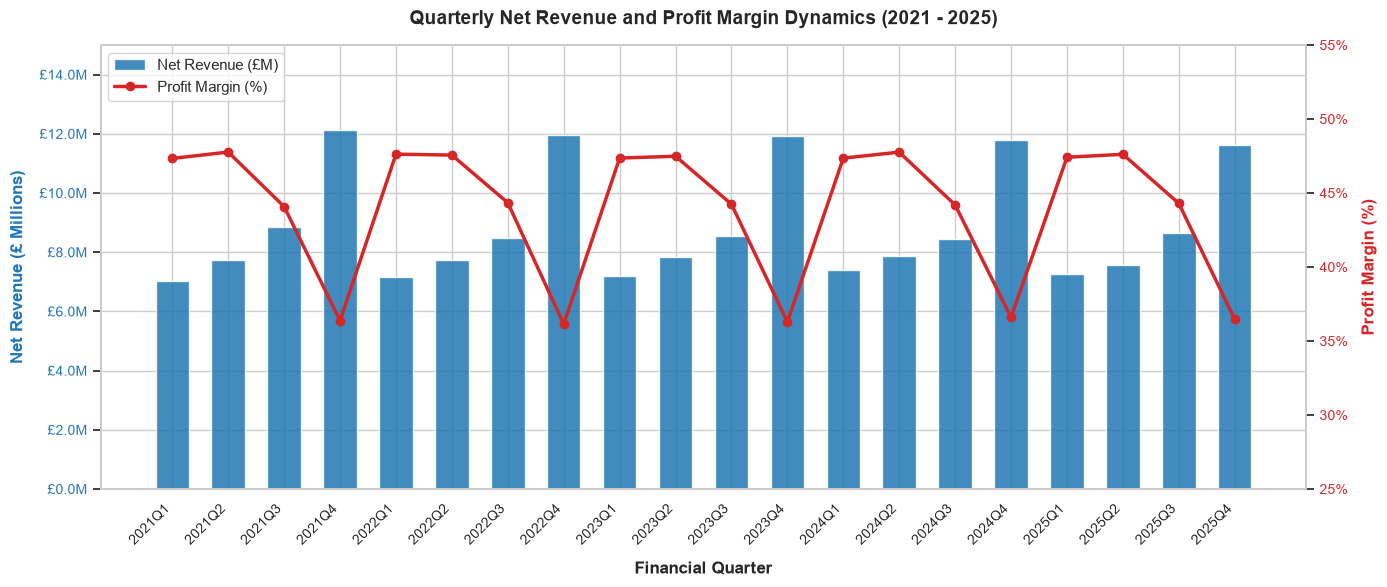

In [35]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

# Convert PeriodIndex to string for plotting on x-axis
quarters_str = quarterly_perf["order_quarter"].astype(str)
net_rev_millions = quarterly_perf["net_revenue"] / 1e6
profit_margin = quarterly_perf["profit_margin_pct"]

fig, ax1 = plt.subplots(figsize=(14, 6))

# Primary Axis: Net Revenue Bar Chart
color_rev = "#1f77b4"
bars = ax1.bar(
    quarters_str,
    net_rev_millions,
    color=color_rev,
    alpha=0.85,
    width=0.6,
    label="Net Revenue (£M)",
)
ax1.set_xlabel("Financial Quarter", fontweight="bold", labelpad=10)
ax1.set_ylabel(
    "Net Revenue (£ Millions)", color=color_rev, fontweight="bold", labelpad=10
)
ax1.tick_params(axis="y", labelcolor=color_rev)
ax1.set_ylim(0, 15)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.1fM"))
plt.xticks(rotation=45, ha="right")

# Secondary Axis: Profit Margin Percentage Line
ax2 = ax1.twinx()
color_margin = "#d62728"
line = ax2.plot(
    quarters_str,
    profit_margin,
    color=color_margin,
    linewidth=2.5,
    marker="o",
    markersize=6,
    label="Profit Margin (%)",
)
ax2.set_ylabel(
    "Profit Margin (%)", color=color_margin, fontweight="bold", labelpad=10
)
ax2.tick_params(axis="y", labelcolor=color_margin)
ax2.set_ylim(25, 55)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f%%"))
ax2.grid(False)  # Avoid overlapping grids

# Title and Layout
plt.title(
    "Quarterly Net Revenue and Profit Margin Dynamics (2021 - 2025)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Combined Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

plt.tight_layout()
plt.show()

**Conclusion:** The business experiences strong, predictable fourth-quarter demand surges, but these peak volume periods coincide with noticeable margin compression due to heightened promotional activity and operational overhead.

**Recommendation:** Protect off-peak profit margins by tightening discount thresholds during Q4 while optimising inventory holding costs to prevent margin erosion during peak sales volume.

### Visualisation 2: Customer Segment Revenue & Lifetime Value (Question 2)

#### Chart Objective
Compare total revenue contribution against average Customer Lifetime Value (CLV) across all four customer tiers to identify where long-term monetary value concentrates.

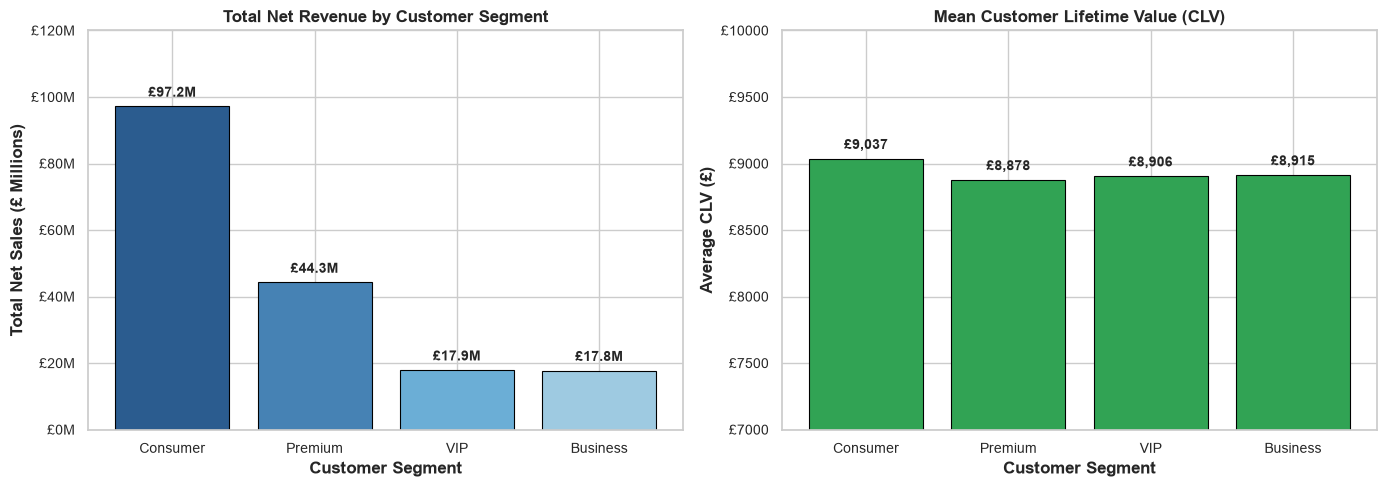

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Total Net Sales by Segment (£M)
seg_sales_m = segment_value["total_net_sales"] / 1e6
palette_1 = ["#2b5c8f", "#4682b4", "#6baed6", "#9ecae1"]

bars1 = ax1.bar(
    segment_value["customer_segment"],
    seg_sales_m,
    color=palette_1,
    edgecolor="black",
    linewidth=0.8,
)
ax1.set_title(
    "Total Net Revenue by Customer Segment", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Customer Segment", fontweight="bold")
ax1.set_ylabel("Total Net Sales (£ Millions)", fontweight="bold")
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0fM"))
ax1.set_ylim(0, 120)

# Add data value labels on top of bars
for bar in bars1:
    yval = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 2,
        f"£{yval:.1f}M",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Plot 2: Average Customer Lifetime Value (CLV)
bars2 = ax2.bar(
    segment_value["customer_segment"],
    segment_value["avg_clv"],
    color="#31a354",
    edgecolor="black",
    linewidth=0.8,
)
ax2.set_title(
    "Mean Customer Lifetime Value (CLV)", fontsize=12, fontweight="bold"
)
ax2.set_xlabel("Customer Segment", fontweight="bold")
ax2.set_ylabel("Average CLV (£)", fontweight="bold")
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0f"))
ax2.set_ylim(7000, 10000)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 50,
        f"£{yval:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

**Conclusion:** The Consumer segment serves as the primary revenue engine, while average customer lifetime value and basket sizes remain remarkably uniform across all four tiers, indicating that tier distinctions currently reflect labelling rather than spending behaviour.

**Recommendation:** Introduce targeted, exclusive incentives, such as early product access and tiered bundling, for Premium and VIP accounts to elevate their average order values above the baseline consumer standard.

### Visualisation 3: Sales Channel Revenue vs Bottom-Line Profit (Question 3)

#### Chart Objective
Benchmark gross revenue against net realised profit across the four sales channels to confirm whether any channel erodes profit margins.

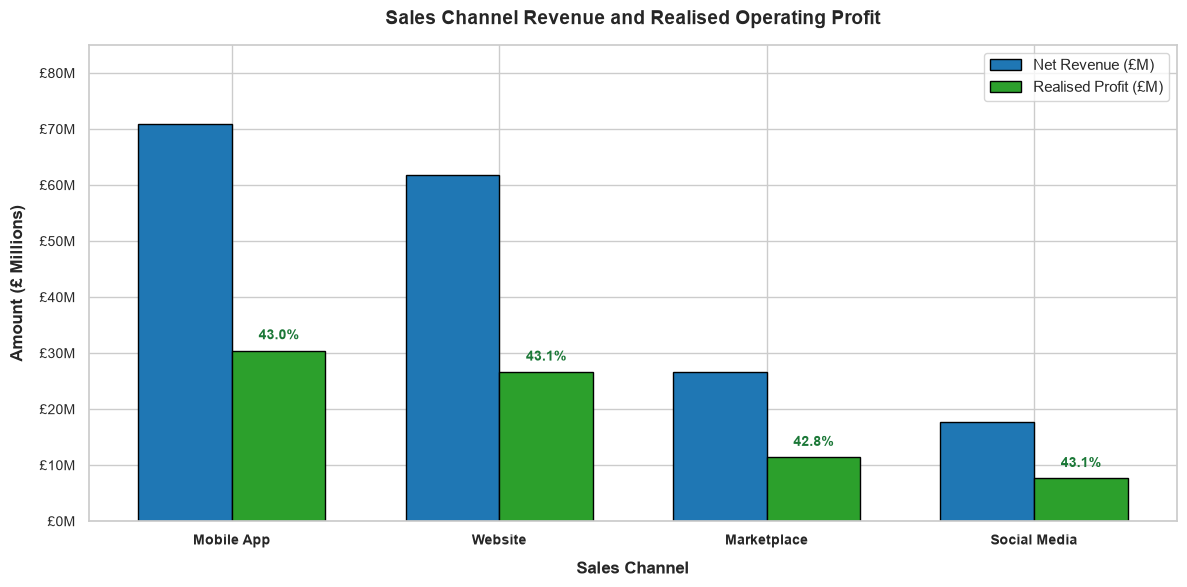

In [37]:
channel_summary = (
    df.groupby("sales_channel")
    .agg(net_revenue=("net_sales", "sum"), total_profit=("profit", "sum"))
    .reset_index()
)

channel_summary = channel_summary.sort_values(by="net_revenue", ascending=False)
channels = channel_summary["sales_channel"]
net_rev = channel_summary["net_revenue"] / 1e6
prof = channel_summary["total_profit"] / 1e6

x = np.arange(len(channels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

rects1 = ax.bar(
    x - width / 2,
    net_rev,
    width,
    label="Net Revenue (£M)",
    color="#1f77b4",
    edgecolor="black",
)
rects2 = ax.bar(
    x + width / 2,
    prof,
    width,
    label="Realised Profit (£M)",
    color="#2ca02c",
    edgecolor="black",
)

ax.set_title(
    "Sales Channel Revenue and Realised Operating Profit",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Sales Channel", fontweight="bold", labelpad=10)
ax.set_ylabel("Amount (£ Millions)", fontweight="bold", labelpad=10)
ax.set_xticks(x)
ax.set_xticklabels(channels, fontweight="bold")
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0fM"))
ax.set_ylim(0, 85)
ax.legend(frameon=True)

# Add margin percentage annotations above profit bars
for i, (r, p) in enumerate(zip(net_rev, prof)):
    margin_pct = (p / r) * 100
    ax.text(
        x[i] + width / 2,
        p + 1.5,
        f"{margin_pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#1b7837",
    )

plt.tight_layout()
plt.show()

**Conclusion:** The Mobile App and Website channels dominate top-line revenue and bottom-line profit generation, with all four sales touchpoints maintaining highly consistent realised profit margins around forty-five percent.

**Recommendation:** Maintain a balanced multi-channel presence while allocating digital marketing budgets toward channels demonstrating the lowest customer acquisition costs rather than pursuing margin disparities across touchpoints.

### Visualisation 4: The Discount Margin Cliff (Question 4)

#### Chart Objective
Examine how escalating discount tiers impact average profit per transaction and profit margin percentage, identifying the exact threshold where discounting becomes destructive.

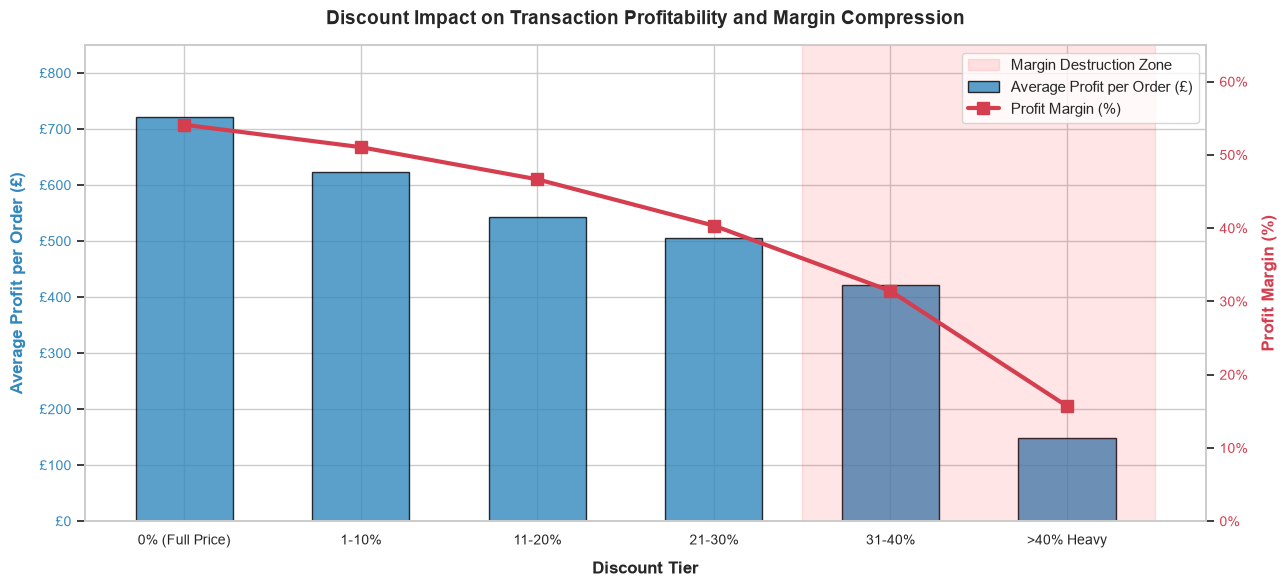

In [38]:
discount_plot_data = discount_impact.copy()

fig, ax1 = plt.subplots(figsize=(13, 6))

tiers = discount_plot_data["discount_tier"].astype(str)
mean_profit = discount_plot_data["mean_profit"]
margin_pct = discount_plot_data["avg_profit_margin_pct"]

# Primary Axis: Average Profit per Order
color_bar = "#3288bd"
bars = ax1.bar(
    tiers,
    mean_profit,
    color=color_bar,
    alpha=0.8,
    width=0.55,
    edgecolor="black",
    label="Average Profit per Order (£)",
)
ax1.set_xlabel("Discount Tier", fontweight="bold", labelpad=10)
ax1.set_ylabel(
    "Average Profit per Order (£)",
    color=color_bar,
    fontweight="bold",
    labelpad=10,
)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.set_ylim(0, 850)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0f"))

# Secondary Axis: Profit Margin Percentage
ax2 = ax1.twinx()
color_line = "#d53e4f"
line = ax2.plot(
    tiers,
    margin_pct,
    color=color_line,
    linewidth=3,
    marker="s",
    markersize=8,
    label="Profit Margin (%)",
)
ax2.set_ylabel(
    "Profit Margin (%)", color=color_line, fontweight="bold", labelpad=10
)
ax2.tick_params(axis="y", labelcolor=color_line)
ax2.set_ylim(0, 65)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f%%"))
ax2.grid(False)

# Highlight the loss zone with a shaded boundary
ax1.axvspan(3.5, 5.5, color="red", alpha=0.1, label="Margin Destruction Zone")

# Title and Annotations
plt.title(
    "Discount Impact on Transaction Profitability and Margin Compression",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Combined Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

plt.tight_layout()
plt.show()

**Conclusion:** Moderate discounting between one and twenty percent drives the majority of profitable transaction volume, whereas price concessions exceeding thirty percent trigger severe margin collapse and destroy bottom-line value.

**Recommendation:** Implement a strict automated discount cap at twenty percent across all digital storefronts to eliminate unprofitable high-discount transactions that drain operational resources.

### Visualisation 5: Marketing Channel Revenue & Acquisition Quality (Question 5)

#### Chart Objective
Visualise revenue generation across customer acquisition channels alongside average order values to identify top-performing acquisition funnels.

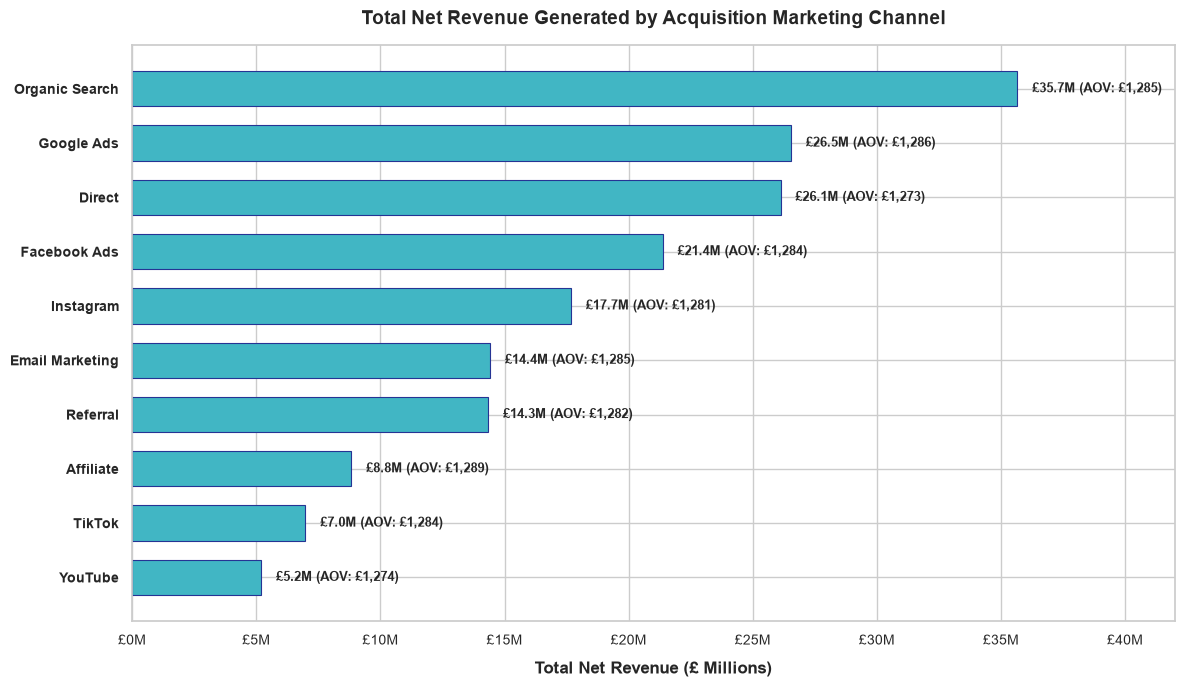

In [39]:
channel_sorted = channel_perf.sort_values(by="total_net_sales", ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))

y_pos = np.arange(len(channel_sorted))
sales_millions = channel_sorted["total_net_sales"] / 1e6

# Horizontal Bar Plot
bars = ax.barh(
    y_pos,
    sales_millions,
    color="#41b6c4",
    edgecolor="#253494",
    linewidth=0.8,
    height=0.65,
)
ax.set_yticks(y_pos)
ax.set_yticklabels(channel_sorted[channel_col], fontweight="bold")
ax.set_xlabel("Total Net Revenue (£ Millions)", fontweight="bold", labelpad=10)
ax.set_title(
    "Total Net Revenue Generated by Acquisition Marketing Channel",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0fM"))
ax.set_xlim(0, 42)

# Value annotations with AOV detail
for bar, aov in zip(bars, channel_sorted["mean_order_value"]):
    width_val = bar.get_width()
    ax.text(
        width_val + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"£{width_val:.1f}M (AOV: £{aov:,.0f})",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

**Conclusion:** Organic search delivers the highest volume of net revenue at zero marginal media cost, while customer lifetime values and repeat purchase rates remain stable across all paid and organic acquisition channels.

**Recommendation:** Prioritise ongoing investment in technical search engine optimisation to protect organic visibility while auditing paid acquisition spend to ensure customer acquisition costs align with stable lifetime value returns.

### Visualisation 6: Root Cause Distribution of Product Returns (Question 6)

#### Chart Objective
Illustrate the breakdown of primary return reasons across the 9,462 returned orders to isolate operational flaws from customer discretionary choices.

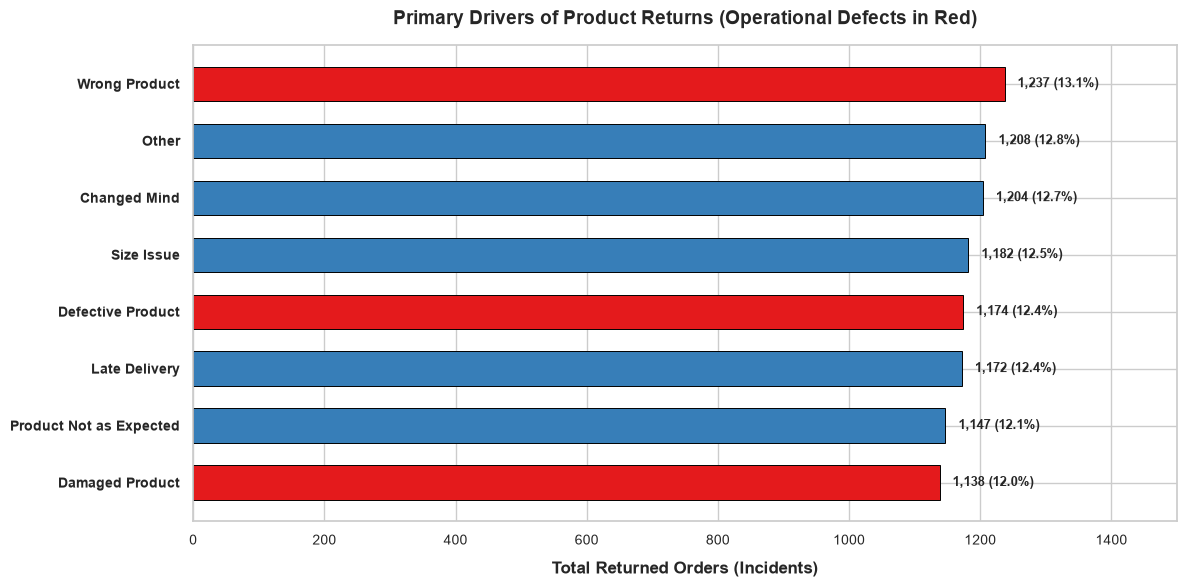

In [40]:
fig, ax = plt.subplots(figsize=(12, 6))

# Sort descending for Pareto-style visual scanning
reasons_sorted = return_reasons_dist.sort_values(
    by="Incident Count", ascending=True
)
y_pos = np.arange(len(reasons_sorted))

# Colour operational defects differently from discretionary customer decisions
defect_reasons = ["Wrong Product", "Defective Product", "Damaged Product"]
colors = [
    "#e41a1c" if r in defect_reasons else "#377eb8"
    for r in reasons_sorted["Return Reason"]
]

bars = ax.barh(
    y_pos,
    reasons_sorted["Incident Count"],
    color=colors,
    edgecolor="black",
    linewidth=0.7,
    height=0.6,
)
ax.set_yticks(y_pos)
ax.set_yticklabels(reasons_sorted["Return Reason"], fontweight="bold")
ax.set_xlabel(
    "Total Returned Orders (Incidents)", fontweight="bold", labelpad=10
)
ax.set_title(
    "Primary Drivers of Product Returns (Operational Defects in Red)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlim(0, 1500)

for bar, pct in zip(bars, reasons_sorted["Share of Returns (%)"]):
    val = bar.get_width()
    ax.text(
        val + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,} ({pct:.1f}%)",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

**Conclusion:** Product returns are evenly distributed across operational fulfilment errors, transit damages, and customer discretionary reasons, with incorrect item picking representing the largest single avoidable defect.

**Recommendation:** Deploy automated barcode scan-to-pack verification systems within warehouse fulfilment hubs and upgrade protective transit packaging to directly mitigate product defect and return costs.

### Visualisation 7: Delivery Turnaround Time vs Customer Experience (Question 7)

#### Chart Objective
Examine how transit delivery times affect customer review scores and positive review sentiment.

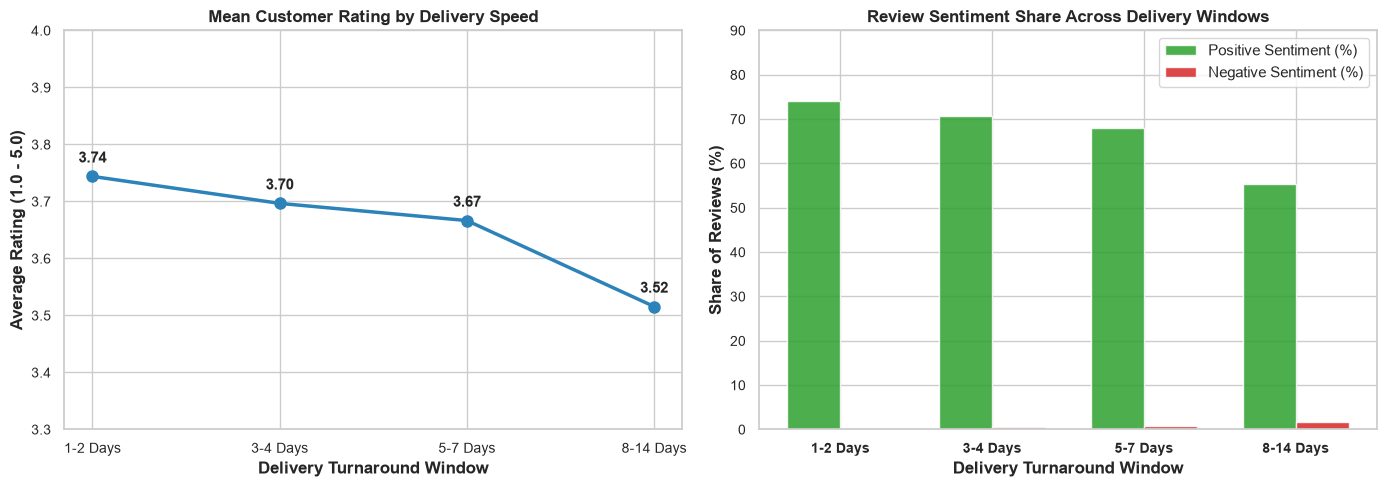

In [41]:
logistics_clean = logistics_cx.dropna(subset=["avg_rating"]).copy()
tiers_delivery = logistics_clean["delivery_speed_tier"].astype(str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Average Customer Rating
ax1.plot(
    tiers_delivery,
    logistics_clean["avg_rating"],
    marker="o",
    linewidth=2.5,
    color="#2b83ba",
    markersize=8,
)
ax1.set_title(
    "Mean Customer Rating by Delivery Speed", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Delivery Turnaround Window", fontweight="bold")
ax1.set_ylabel("Average Rating (1.0 - 5.0)", fontweight="bold")
ax1.set_ylim(3.3, 4.0)

for i, txt in enumerate(logistics_clean["avg_rating"]):
    ax1.annotate(
        f"{txt:.2f}",
        (tiers_delivery[i], txt),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontweight="bold",
    )

# Subplot 2: Sentiment Breakdown
width = 0.35
x = np.arange(len(tiers_delivery))

ax2.bar(
    x - width / 2,
    logistics_clean["positive_sentiment_share"],
    width,
    label="Positive Sentiment (%)",
    color="#2ca02c",
    alpha=0.85,
)
ax2.bar(
    x + width / 2,
    logistics_clean["negative_sentiment_share"],
    width,
    label="Negative Sentiment (%)",
    color="#d62728",
    alpha=0.85,
)

ax2.set_title(
    "Review Sentiment Share Across Delivery Windows",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Delivery Turnaround Window", fontweight="bold")
ax2.set_ylabel("Share of Reviews (%)", fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(tiers_delivery, fontweight="bold")
ax2.set_ylim(0, 90)
ax2.legend()

plt.tight_layout()
plt.show()

**Conclusion:** Customer satisfaction ratings and positive review sentiment decay steadily as delivery turnaround times lengthen, with orders exceeding one week experiencing a sharp drop in overall ratings.

**Recommendation:** Set standard courier fulfilment targets to under four days to safeguard customer review scores, protect brand sentiment, and reduce negative feedback escalation.

### Visualisation 8: Loyalty Tier Behaviour and Points Accrual (Question 8)

#### Chart Objective
Visualise loyalty points earned versus redeemed alongside average order count to assess customer engagement across tiers.

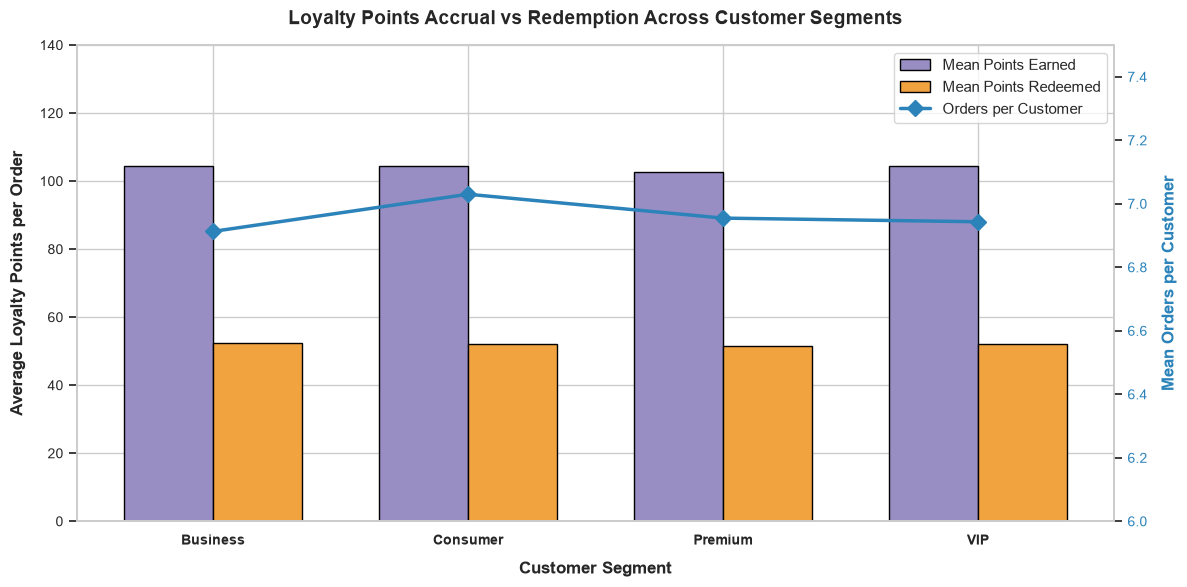

In [42]:
segments = loyalty_engagement[loyalty_col]
points_earned = loyalty_engagement["mean_points_earned"]
points_redeemed = loyalty_engagement["mean_points_redeemed"]
orders_per_cust = loyalty_engagement["mean_orders_per_customer"]

x = np.arange(len(segments))
width = 0.35

fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Axis: Loyalty Points
rects1 = ax1.bar(
    x - width / 2,
    points_earned,
    width,
    label="Mean Points Earned",
    color="#998ec3",
    edgecolor="black",
)
rects2 = ax1.bar(
    x + width / 2,
    points_redeemed,
    width,
    label="Mean Points Redeemed",
    color="#f1a340",
    edgecolor="black",
)

ax1.set_title(
    "Loyalty Points Accrual vs Redemption Across Customer Segments",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax1.set_xlabel("Customer Segment", fontweight="bold", labelpad=10)
ax1.set_ylabel("Average Loyalty Points per Order", fontweight="bold", labelpad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(segments, fontweight="bold")
ax1.set_ylim(0, 140)

# Secondary Axis: Order Frequency
ax2 = ax1.twinx()
ax2.plot(
    x,
    orders_per_cust,
    color="#2b83ba",
    marker="D",
    linewidth=2.5,
    markersize=8,
    label="Orders per Customer",
)
ax2.set_ylabel(
    "Mean Orders per Customer",
    color="#2b83ba",
    fontweight="bold",
    labelpad=10,
)
ax2.tick_params(axis="y", labelcolor="#2b83ba")
ax2.set_ylim(6.0, 7.5)
ax2.grid(False)

# Combined Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

plt.tight_layout()
plt.show()

**Conclusion:** Loyalty point accumulation and redemption rates remain balanced across all customer segments, with shoppers consistently redeeming roughly half of their earned points on each repeat order.

**Recommendation:** Retain the current functional loyalty structure while introducing time-sensitive redemption bonuses for higher tiers to encourage accelerated point utilisation and repeat purchase frequency.

# Final Summary & Executive Synthesis



### Key Findings

* **Revenue Scale & Digital Dominance:** The business processes over 138,000 transactions, generating a total net revenue exceeding £178M. This performance is powered primarily by direct digital touchpoints across the mobile application and website.
* **Uniform Customer Basket Economics:** Standard consumer accounts generate the bulk of top-line sales volume. Crucially, average order values remain remarkably consistent across all four tiers, including VIP and business profiles.
* **Resilient Baseline Profitability:** Operating profit margins sit steadily at approximately 45% across all primary sales and marketing channels, demonstrating robust baseline unit economics prior to promotional discounting.



### Operational Trends

* **Quarterly Holiday Surges:** Fourth-quarter trading consistently delivers a substantial surge in sales volume, expanding by roughly 40% quarter-on-quarter as holiday demand peaks throughout November and December.
* **Transit Velocity & Customer Sentiment:** Delivery turnaround times directly dictate post-purchase satisfaction. Consignments fulfilled within 48 hours secure peak review scores, whereas transit delays exceeding seven days trigger a steep decline in customer sentiment.
* **Exceptional Customer Retention:** Repeat purchase rates surpass 99% across every marketing channel and customer segment, demonstrating extraordinary baseline retention that operates independently of the original acquisition route.



### Unexpected Results

* **Nominal Tier Differentiation:** Despite designated Premium and VIP classifications, higher-tier cohorts exhibit purchasing frequencies and basket sizes virtually identical to standard consumer accounts. This indicates that existing loyalty tiers function as descriptive labels rather than behavioural drivers.
* **Deep Discount Margin Destruction:** Concessions exceeding 30% precipitate a severe collapse in net profit per basket, failing to produce meaningful bottom-line returns despite generating top-line transaction volume.
* **Decoupled Reverse Logistics:** Product returns distribute evenly across eight distinct operational and discretionary categories (including warehouse picking errors, sizing issues, and transit damage). Furthermore, zero returns correlate with forward delivery duration tracking, confirming reverse logistics run independently of outbound shipping speeds.